<a href="https://colab.research.google.com/github/malhotrax/Heart-Disease-Prediction/blob/main/Heart_Disease_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from matplotlib import pyplot as plt

In [2]:
keras.utils.set_random_seed(42)

In [3]:
data_uri = "http://storage.googleapis.com/download.tensorflow.org/data/heart.csv"


In [4]:
df  = pd.read_csv(data_uri)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    object 
 13  target    303 non-null    int64  
dtypes: float64(1), int64(12), object(1)
memory usage: 33.3+ KB


In [5]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0,fixed,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3,normal,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2,reversible,0
3,37,1,3,130,250,0,0,187,0,3.5,3,0,normal,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0,normal,0


In [6]:
df.target.value_counts(normalize=True, dropna=False)

,proportion
target,
0,0.726073
1,0.273927


In [7]:
categorical_variables = ['sex', 'cp', 'restecg', 'exang', 'ca', 'thal','fbs']
numerics = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak','slope']

In [8]:
df = pd.get_dummies(df, columns= categorical_variables, dtype=int)


In [9]:
df.head()

,age,trestbps,chol,thalach,oldpeak,slope,target,sex_0,sex_1,cp_0,...,ca_1,ca_2,ca_3,thal_1,thal_2,thal_fixed,thal_normal,thal_reversible,fbs_0,fbs_1
0,63,145,233,150,2.3,3,0,0,1,0,...,0,0,0,0,0,1,0,0,0,1
1,67,160,286,108,1.5,2,1,0,1,0,...,0,0,1,0,0,0,1,0,1,0
2,67,120,229,129,2.6,2,0,0,1,0,...,0,1,0,0,0,0,0,1,1,0
3,37,130,250,187,3.5,3,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
4,41,130,204,172,1.4,1,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


In [10]:
test_df = df.sample(frac=0.2, random_state= 42)
train_df = df.drop(test_df.index)

In [11]:
train_df.shape

(242, 30)

In [12]:
# Standarizing
means = train_df[numerics].mean()
std = train_df[numerics].std()

In [13]:
train_df[numerics] = (train_df[numerics] - means) / std
test_df[numerics] = (test_df[numerics] - means) / std

In [14]:
train = train_df.to_numpy()
test = test_df.to_numpy()

In [32]:
train_x = np.delete(train, 6, axis = 1)
test_x = np.delete(test, 6, axis = 1)

In [34]:
train_y = train[:, 6]
test_y = test[:, 6]

(242,)
(61, 29)


In [17]:
shape = train_x.shape[1]
shape

29

In [18]:
# Model
input = keras.Input(shape = (shape,))
h = keras.layers.Dense(16, activation = 'relu')(input)
output = keras.layers.Dense(1,activation='sigmoid')(h)

model = keras.Model(input, output)

In [19]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 29)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 497 (1.94 KB)

 Trainable params: 497 (1.94 KB)

 Non-trainable params: 0 (0.00 B)

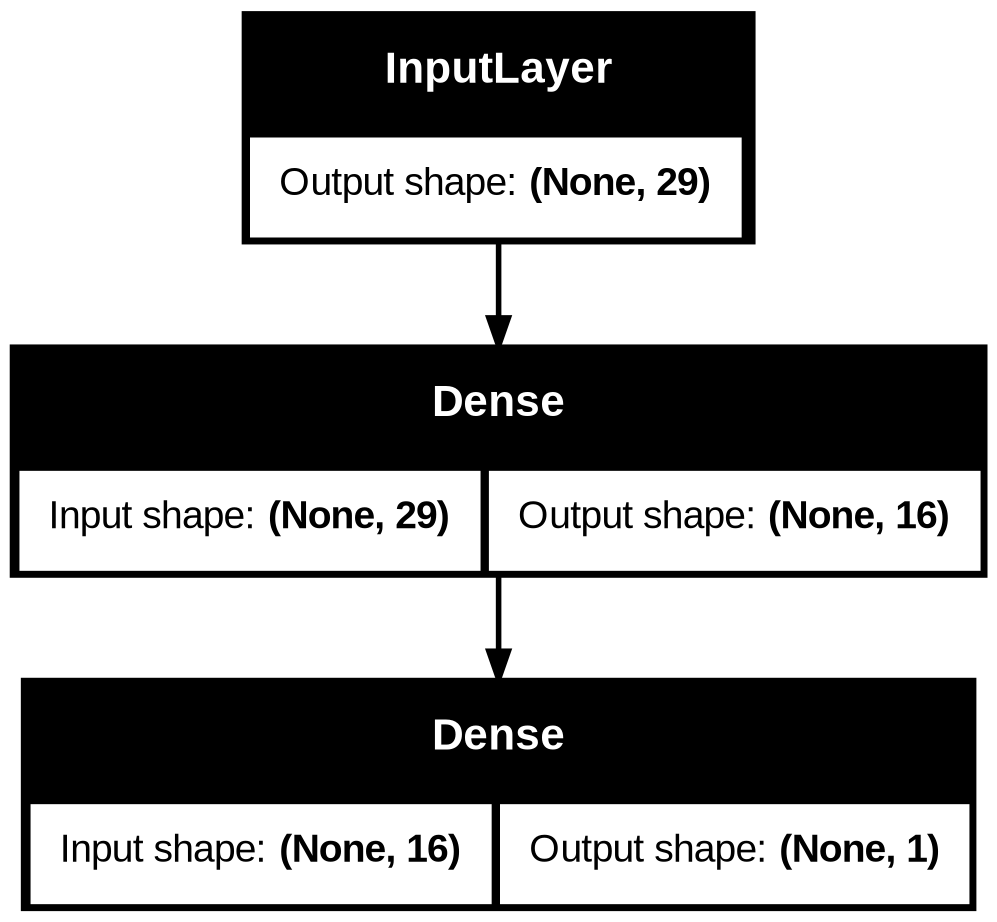

In [20]:
keras.utils.plot_model(model,show_shapes=True)

In [21]:
model.compile(optimizer='adam', loss= 'binary_crossentropy', metrics=['accuracy'])

In [22]:
history = model.fit(
    train_x,
    train_y,
    batch_size=32,
    epochs= 300,
    validation_split=0.2,
    verbose = 1
)

Epoch 1/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 149ms/step - accuracy: 0.3886 - loss: 0.7989 - val_accuracy: 0.4082 - val_loss: 0.7446
Epoch 2/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4197 - loss: 0.7636 - val_accuracy: 0.4694 - val_loss: 0.7182
Epoch 3/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4663 - loss: 0.7364 - val_accuracy: 0.5306 - val_loss: 0.6954
Epoch 4/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5026 - loss: 0.7117 - val_accuracy: 0.6122 - val_loss: 0.6746
Epoch 5/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5544 - loss: 0.6888 - val_accuracy: 0.5918 - val_loss: 0.6550
Epoch 6/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6062 - loss: 0.6676 - val_accuracy: 0.5918 - val_loss: 0.6366
Epoch 7/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6425 - loss: 0.6474 - val_accuracy: 0.6327 - val_loss: 0.6195
Epoch 8/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6580 - loss: 0.6276 - val_accuracy: 0.6735 - val_loss

In [23]:
history_dict  = history.history
history_dict.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [25]:
loss_values = history_dict['loss']
val_loss_values = history_dict['val_loss']
epochs = range(1, len(loss_values) + 1)


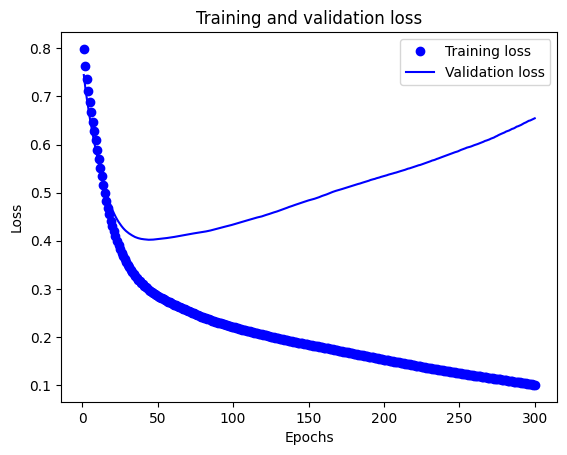

In [27]:
plt.plot(epochs, loss_values, 'bo', label='Training loss')
plt.plot(epochs, val_loss_values, 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

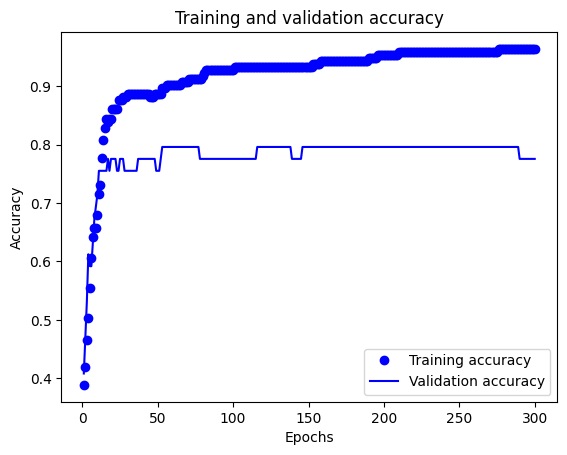

In [28]:
plt.clf()
acc = history_dict['accuracy']
val_acc = history_dict['val_accuracy']
epochs = range(1, len(acc) + 1)
plt.plot(epochs, acc, 'bo', label = 'Training accuracy')
plt.plot(epochs, val_acc, 'b', label = 'Validation accuracy')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

In [36]:
model.evaluate(test_x, test_y)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step - accuracy: 0.8033 - loss: 0.4875


[0.4875447154045105, 0.8032786846160889]

In [38]:
model.predict(np.expand_dims(test_x[4], axis=0))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step


array([[0.04879594]], dtype=float32)

In [39]:
test_y[4]

np.float64(0.0)